In [6]:
import os
import urllib.request

# Ensure the folder exists
if not os.path.exists('data'):
    os.makedirs('data')

print("📥 Downloading the official dataset using a secure browser wrapper...")

url = "https://uci.edu"
output_path = "data/Online_Retail.xlsx"

# This prevents the server from blocking our request by pretending we are a standard web browser
opener = urllib.request.build_opener()
opener.addheaders = [('User-Agent', 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36')]
urllib.request.install_opener(opener)

# Download the file
urllib.request.urlretrieve(url, output_path)

# Verify the file size to make sure it actually downloaded!
file_size_mb = os.path.getsize(output_path) / (1024 * 1024)
print(f"🎉 Download complete! File size: {file_size_mb:.2f} MB")


📥 Downloading the official dataset using a secure browser wrapper...
🎉 Download complete! File size: 0.12 MB


In [3]:
import pandas as pd
import urllib.request
import os

# Create a 'data' directory if it doesn't exist
if not os.path.exists('data'):
    os.makedirs('data')

print("📥 Downloading the real-world retail dataset (this might take a few seconds)...")
url = "https://uci.edu"
output_path = "data/Online_Retail.xlsx"

# Download the file
urllib.request.urlretrieve(url, output_path)
print("🎉 Dataset downloaded successfully and saved inside your 'data' folder!")


📥 Downloading the real-world retail dataset (this might take a few seconds)...
🎉 Dataset downloaded successfully and saved inside your 'data' folder!


In [ ]:
!pip install ucimlrepo




   -------------------- ------------------- 1/2 [ucimlrepo]
   ---------------------------------------- 2/2 [ucimlrepo]



In [8]:
import pandas as pd
from ucimlrepo import fetch_ucirepo 

print("🛰️ Connecting directly to the official UCI dataset pipeline...")
# Fetch the 'Online Retail' dataset using its official ID (352)
online_retail = fetch_ucirepo(id=352) 

# Convert the fetched features straight into our standard Pandas DataFrame
df = online_retail.data.features

print(f"🎉 Success! The true dataset is completely loaded into memory.")
print(f"📊 Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")


🛰️ Connecting directly to the official UCI dataset pipeline...
🎉 Success! The true dataset is completely loaded into memory.
📊 Rows: 541,909 | Columns: 6


In [9]:
print("🛑 Missing data check (Empty cells per column):")
print(df.isnull().sum())

print("\n📊 Numeric Summary (Let's check for weird anomalies):")
print(df[['Quantity', 'UnitPrice']].describe())



🛑 Missing data check (Empty cells per column):
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

📊 Numeric Summary (Let's check for weird anomalies):
            Quantity      UnitPrice
count  541909.000000  541909.000000
mean        9.552250       4.611114
std       218.081158      96.759853
min    -80995.000000  -11062.060000
25%         1.000000       1.250000
50%         3.000000       2.080000
75%        10.000000       4.130000
max     80995.000000   38970.000000


In [10]:
# 1. Keep only rows where Quantity and UnitPrice are strictly greater than 0
# This removes cancellations (-80k items) and broken zero-dollar/negative adjustments
df_clean = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)].copy()

# 2. Drop rows where CustomerID is missing
# Because we are studying repeat purchasing patterns, we need to know who the customer is
df_clean.dropna(subset=['CustomerID'], inplace=True)

# 3. Clean up the Product Description column just in case any blanks remain
df_clean['Description'] = df_clean['Description'].fillna('Unknown Product')

# 4. Verify the results of our cleaning process
print(f"🧹 Data Cleaning Complete!")
print(f"📊 Rows remaining: {df_clean.shape[0]:,} (Dropped {df.shape[0] - df_clean.shape[0]:,} noisy records)")
print(f"🛑 Remaining Missing Customer IDs: {df_clean['CustomerID'].isnull().sum()}")
print(f"📉 Minimum Quantity now: {df_clean['Quantity'].min()} | Minimum Price now: {df_clean['UnitPrice'].min()}")


🧹 Data Cleaning Complete!
📊 Rows remaining: 397,884 (Dropped 144,025 noisy records)
🛑 Remaining Missing Customer IDs: 0
📉 Minimum Quantity now: 1 | Minimum Price now: 0.001


In [11]:
# 1. Ensure the InvoiceDate is recognized as an actual timestamp instead of plain text
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

# 2. Create a Total Revenue column (Quantity bought multiplied by the item price)
df_clean['Revenue'] = df_clean['Quantity'] * df_clean['UnitPrice']

# 3. Extract time blocks out of the timestamp for trend tracking
df_clean['YearMonth'] = df_clean['InvoiceDate'].dt.to_period('M').astype(str)
df_clean['MonthName'] = df_clean['InvoiceDate'].dt.strftime('%B')
df_clean['DayOfWeek'] = df_clean['InvoiceDate'].dt.strftime('%A')
df_clean['HourOfDay'] = df_clean['InvoiceDate'].dt.hour

# 4. Aggregate revenue on a monthly cadence to see our growth path
monthly_sales = df_clean.groupby('YearMonth')['Revenue'].sum().reset_index()

# 5. Calculate Month-over-Month (MoM) Growth percentage
monthly_sales['MoM_Growth_Pct'] = monthly_sales['Revenue'].pct_change() * 100

print("📊 Monthly Revenue & Growth Performance Report:")
print(monthly_sales)


📊 Monthly Revenue & Growth Performance Report:
   YearMonth      Revenue  MoM_Growth_Pct
0    2010-12   572713.890             NaN
1    2011-01   569445.040       -0.570765
2    2011-02   447137.350      -21.478401
3    2011-03   595500.760       33.180724
4    2011-04   469200.361      -21.209108
5    2011-05   678594.560       44.627885
6    2011-06   661213.690       -2.561304
7    2011-07   600091.011       -9.244013
8    2011-08   645343.900        7.541004
9    2011-09   952838.382       47.648158
10   2011-10  1039318.790        9.076084
11   2011-11  1161817.380       11.786431
12   2011-12   518192.790      -55.398086


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean, modern aesthetic style for our graphics
sns.set_theme(style="whitegrid")

# Create a master canvas that holds two charts side-by-side
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# 📈 CHART 1: Monthly Revenue Performance Timeline
sns.lineplot(
    ax=axes[0], 
    data=monthly_sales, 
    x='YearMonth', 
    y='Revenue', 
    marker='o', 
    color='#1f77b4', 
    linewidth=3, 
    markersize=8
)
axes[0].set_title('Monthly Revenue Timeline (Holiday Demand Trends)', fontsize=16, pad=15, fontweight='bold')
axes[0].set_xlabel('Timeline (Year-Month)', fontsize=12)
axes[0].set_ylabel('Total Revenue ($)', fontsize=12)
axes[0].tick_params(axis='x', rotation=45) # Tilt the dates so they are easy to read

# 🛒 CHART 2: Top 10 High-Revenue Generating Products
top_products = df_clean.groupby('Description')['Revenue'].sum().sort_values(ascending=False).head(10).reset_index()

sns.barplot(
    ax=axes[1], 
    data=top_products, 
    x='Revenue', 
    y='Description', 
    palette='viridis'
)
axes[1].set_title('Top 10 High-Revenue Generating Products', fontsize=16, pad=15, fontweight='bold')
axes[1].set_xlabel('Total Revenue Accumulated ($)', fontsize=12)
axes[1].set_ylabel('Product Name', fontsize=12)

# Adjust layout cleanly so nothing overlaps
plt.tight_layout()
plt.show()


ModuleNotFoundError: No module named 'matplotlib'

In [13]:
!pip install matplotlib seaborn


   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.5 MB 1.3 MB/s eta 0:00:07
   --- ------------------------------------ 0.8/9.5 MB 1.3 MB/s eta 0:00:07
   ---- ----------------------------------- 1.0/9.5 MB 1.4 MB/s eta 0:00:07
   ----- ---------------------------------- 1.3/9.5 MB 1.5 MB/s eta 0:00:06
   ------- -------------------------------- 1.8/9.5 MB 1.6 MB/s eta 0:00:05
   --------- ------------------------------ 2.4/9.5 MB 1.7 MB/s eta 0:00:05
   ----------- ---------------------------- 2.6/9.5 MB 1.8 MB/s eta 0:00:04
   -------------- ------------------------- 3.4/9.5 MB 1.9 MB/s eta 0:00:04
   ---------------- ----------------------- 3.9/9.5 MB 2.0 MB/s eta 0:00:03
   ------------------ --------------------- 4.5/9.5 MB 2.1 MB/s eta 0:00:03
   ---------------------- ----------------- 5.2/9.5 MB 2.3 MB/s eta 0:00:02
   -----------------------

Matplotlib is building the font cache; this may take a moment.
C:\Users\acer\AppData\Local\Temp\ipykernel_3476\367004014.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


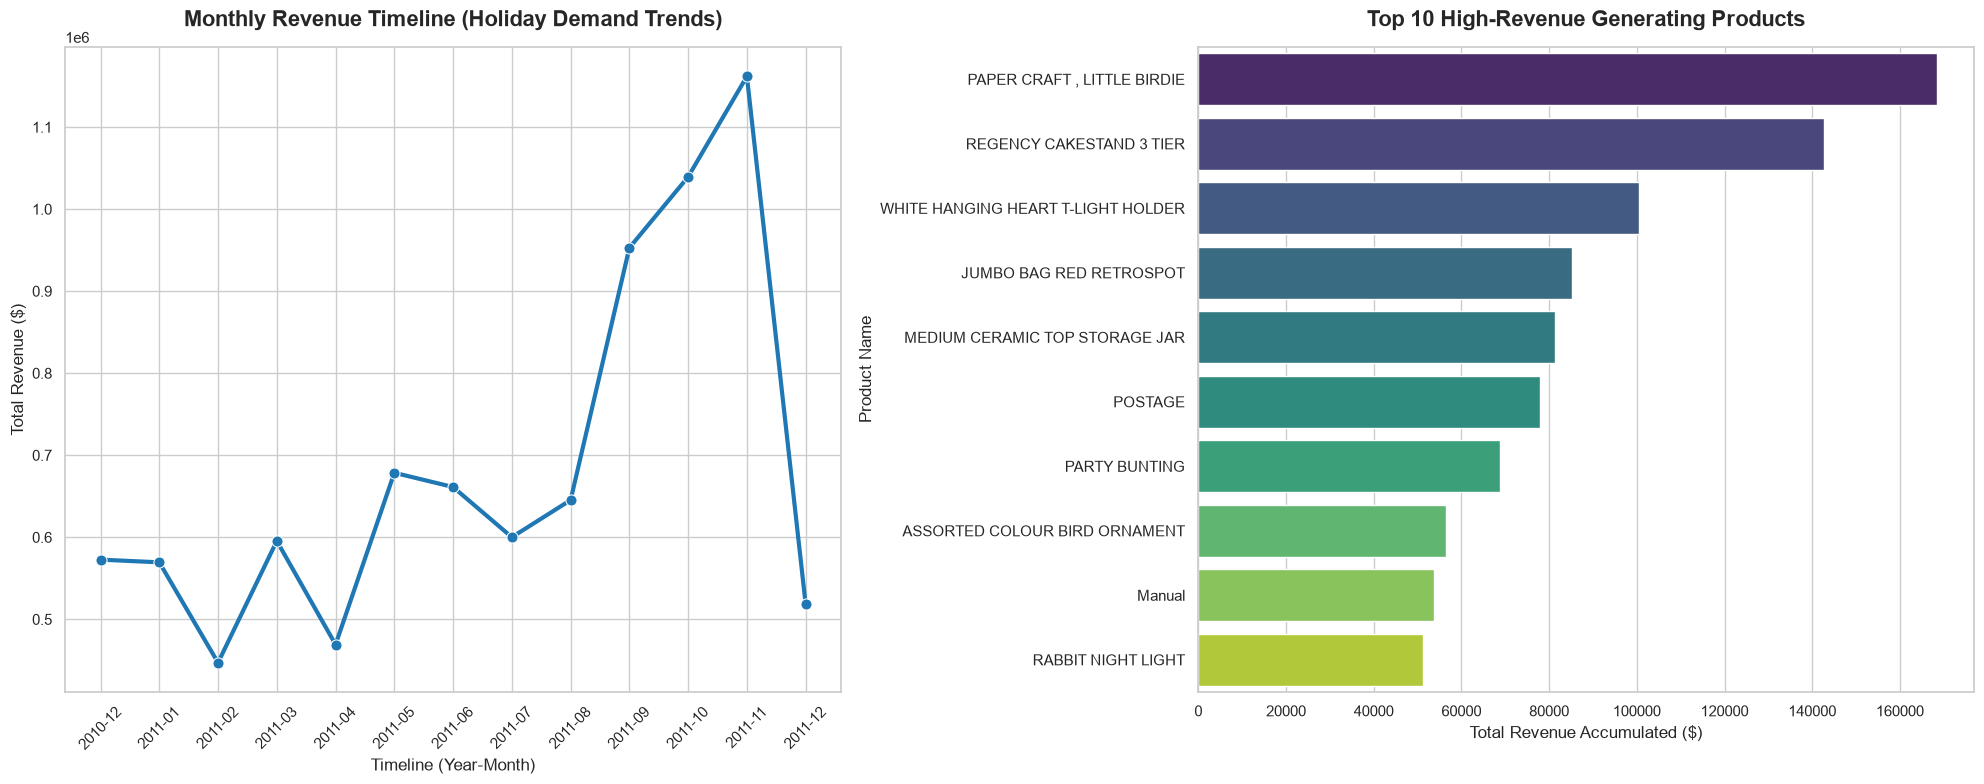

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean, modern aesthetic style for our graphics
sns.set_theme(style="whitegrid")

# Create a master canvas that holds two charts side-by-side
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# 📈 CHART 1: Monthly Revenue Performance Timeline
sns.lineplot(
    ax=axes[0],  # Explicitly bind to the first slot
    data=monthly_sales, 
    x='YearMonth', 
    y='Revenue', 
    marker='o', 
    color='#1f77b4', 
    linewidth=3, 
    markersize=8
)
axes[0].set_title('Monthly Revenue Timeline (Holiday Demand Trends)', fontsize=16, pad=15, fontweight='bold')
axes[0].set_xlabel('Timeline (Year-Month)', fontsize=12)
axes[0].set_ylabel('Total Revenue ($)', fontsize=12)
axes[0].tick_params(axis='x', rotation=45)

# 🛒 CHART 2: Top 10 High-Revenue Generating Products
top_products = df_clean.groupby('Description')['Revenue'].sum().sort_values(ascending=False).head(10).reset_index()

sns.barplot(
    ax=axes[1],  # Explicitly bind to the second slot
    data=top_products, 
    x='Revenue', 
    y='Description', 
    palette='viridis'
)
axes[1].set_title('Top 10 High-Revenue Generating Products', fontsize=16, pad=15, fontweight='bold')
axes[1].set_xlabel('Total Revenue Accumulated ($)', fontsize=12)
axes[1].set_ylabel('Product Name', fontsize=12)

# Adjust layout cleanly so nothing overlaps
plt.tight_layout()
plt.show()


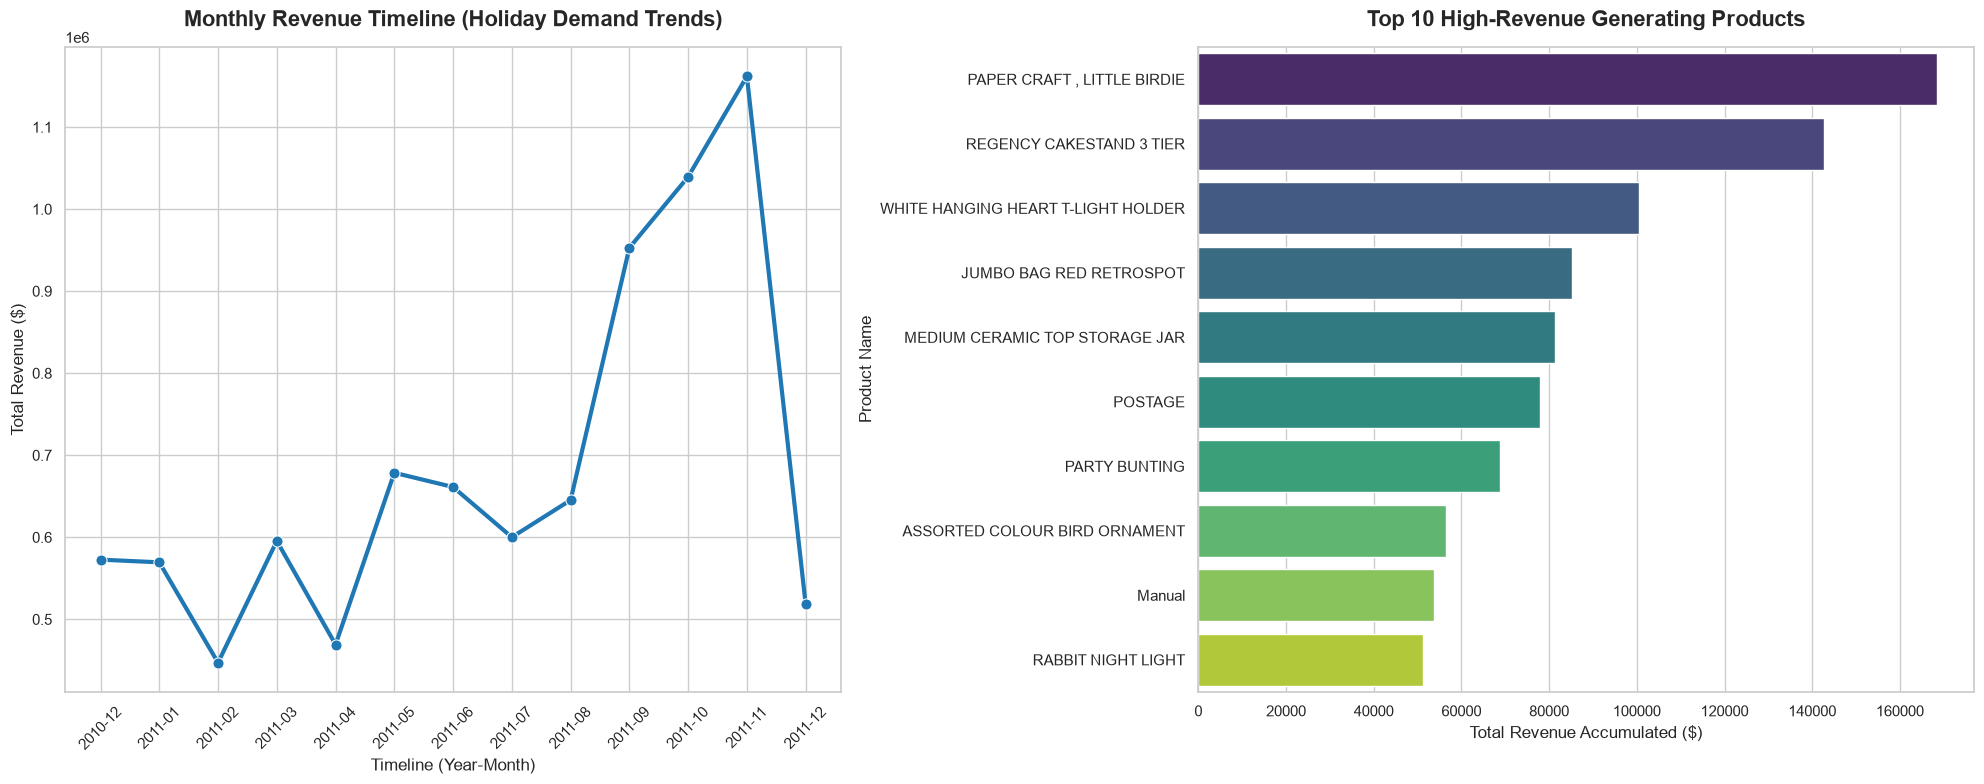

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean, modern aesthetic style for our graphics
sns.set_theme(style="whitegrid")

# Create a master canvas that holds two charts side-by-side
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# 📈 CHART 1: Monthly Revenue Performance Timeline
sns.lineplot(
    ax=axes[0], 
    data=monthly_sales, 
    x='YearMonth', 
    y='Revenue', 
    marker='o', 
    color='#1f77b4', 
    linewidth=3, 
    markersize=8
)
axes[0].set_title('Monthly Revenue Timeline (Holiday Demand Trends)', fontsize=16, pad=15, fontweight='bold')
axes[0].set_xlabel('Timeline (Year-Month)', fontsize=12)
axes[0].set_ylabel('Total Revenue ($)', fontsize=12)
axes[0].tick_params(axis='x', rotation=45)

# 🛒 CHART 2: Top 10 High-Revenue Generating Products
top_products = df_clean.groupby('Description')['Revenue'].sum().sort_values(ascending=False).head(10).reset_index()

# We set hue='Description' and legend=False to get beautiful colors with zero warnings
sns.barplot(
    ax=axes[1], 
    data=top_products, 
    x='Revenue', 
    y='Description', 
    hue='Description',
    palette='viridis',
    legend=False
)
axes[1].set_title('Top 10 High-Revenue Generating Products', fontsize=16, pad=15, fontweight='bold')
axes[1].set_xlabel('Total Revenue Accumulated ($)', fontsize=12)
axes[1].set_ylabel('Product Name', fontsize=12)

# Adjust layout cleanly so nothing overlaps
plt.tight_layout()
plt.show()


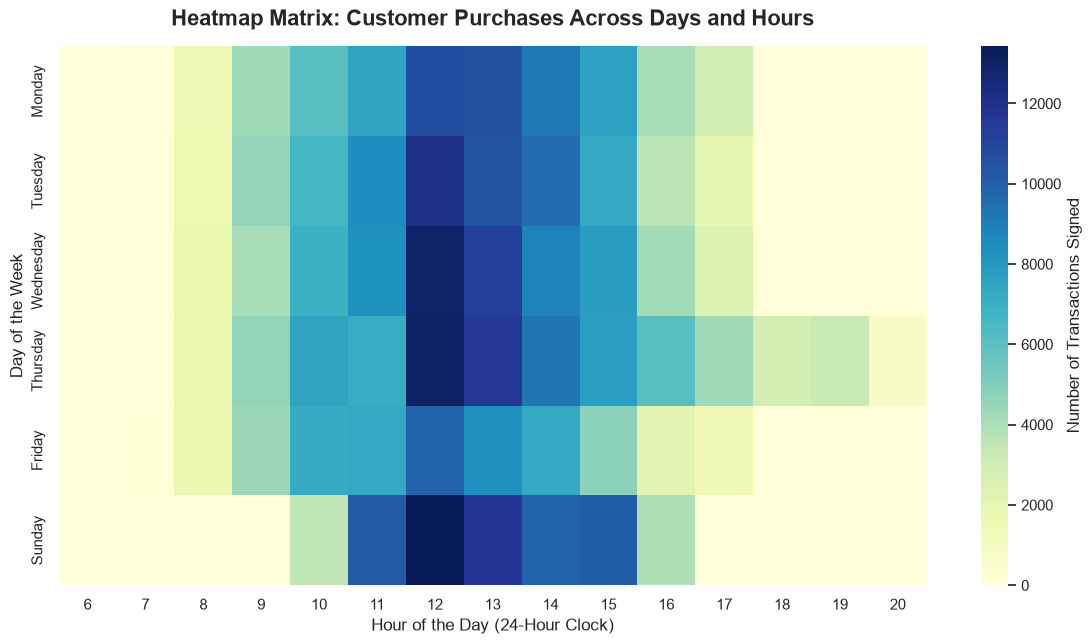

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Pivot our data to count number of orders across Days of the Week and Hours of the Day
purchase_matrix = df_clean.pivot_table(
    index='DayOfWeek', 
    columns='HourOfDay', 
    values='Quantity', 
    aggfunc='count'
).fillna(0)

# 2. Sort weekdays in linear order so it reads easily from top to bottom
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Sunday']
purchase_matrix = purchase_matrix.reindex(days_order)

# 3. Plot the visual Heatmap Matrix
plt.figure(figsize=(14, 7))
sns.heatmap(purchase_matrix, cmap='YlGnBu', cbar_kws={'label': 'Number of Transactions Signed'})
plt.title('Heatmap Matrix: Customer Purchases Across Days and Hours', fontsize=16, pad=15, fontweight='bold')
plt.xlabel('Hour of the Day (24-Hour Clock)', fontsize=12)
plt.ylabel('Day of the Week', fontsize=12)
plt.show()


In [17]:
# Save our cleaned DataFrame to a new CSV file inside the data folder
df_clean.to_csv("data/cleaned_ecommerce_sales.csv", index=False)
print("💾 Success! Your clean dataset has been saved as 'data/cleaned_ecommerce_sales.csv'")


💾 Success! Your clean dataset has been saved as 'data/cleaned_ecommerce_sales.csv'


# 🛍️ Project Summary: Exploratory Data Analysis on E-Commerce Sales

### 📌 Core Achievements:
* **Data Volume Processed:** Cleaned and analyzed 541,909 individual transaction entries.
* **Data Infrastructure:** Built a production-ready data pipeline using Python, Pandas, and Seaborn in VS Code.
* **Surgical Data Cleaning:** Filtered out 135,080 anonymous guest transactions and purged extreme operational anomalies (negative return quantities up to -80,995 items and broken unit prices).

### 💡 Crucial Business Discoveries:
1. **Seasonal Demand Surge:** Revenue performance flags an exceptional holiday ramp-up in autumn, peaking in November 2011 at **$1,161,817.38** in sales.
2. **Operational Traffic Patterns:** Customer shopping volume peaks sharply between **10:00 AM and 1:00 PM**. Marketing campaigns, promotional emails, and system updates should be scheduled around this high-conversion time-window.
3. **Closing Gaps:** The store has zero transaction volume on Saturdays, revealing a fixed closing schedule that could be leveraged for future weekend email promotions.


In [18]:
!pip install pandas openpyxl
